# MPIIGaze Gaze Estimation with CNN

이 노트북은 데이터 준비, 모델 구성, 학습, 추론, 결과 분석을 순서대로 수행합니다.

- 입력: eye image (1, 36, 60), head pose (2,)
- 출력: 2D gaze (yaw, pitch)
- loss: cosine loss on unit gaze vectors
- metric: angular error (degrees)
- evaluation: leave-one-person-out


In [3]:
import os
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt

torch.backends.cudnn.benchmark = True

import reader
from preprocess.mpii_norm import gaze_to_3d

ROOT = Path.cwd()
DATA_ROOT = ROOT / "data" / "EyeBased" / "MPIIGaze"
LABEL_ROOT = DATA_ROOT / "Label"
IMAGE_ROOT = DATA_ROOT / "Image"
PERSONS = [f"p{k:02d}" for k in range(15)]

IMG_MEAN = None
IMG_STD = None
HEAD_MEAN = None
HEAD_STD = None

print("Data root:", DATA_ROOT)
print("Persons:", PERSONS)


Data root: /home/jinju/gaze_estimation/data/EyeBased/MPIIGaze
Persons: ['p00', 'p01', 'p02', 'p03', 'p04', 'p05', 'p06', 'p07', 'p08', 'p09', 'p10', 'p11', 'p12', 'p13', 'p14']


In [4]:
def angular_error(pred, gt):
    """pred, gt: (N, 2) yaw/pitch radians -> (N,) degrees."""
    a, b = gaze_to_3d(pred), gaze_to_3d(gt)
    cos = np.sum(a * b, axis=-1) / (
        np.linalg.norm(a, axis=-1) * np.linalg.norm(b, axis=-1)
    )
    return np.degrees(np.arccos(np.clip(cos, -1.0, 1.0)))


def gaze_to_3d_torch(gaze):
    yaw, pitch = gaze[..., 0], gaze[..., 1]
    return torch.stack(
        [
            -torch.cos(pitch) * torch.sin(yaw),
            -torch.sin(pitch),
            -torch.cos(pitch) * torch.cos(yaw),
        ],
        dim=-1,
    )


def compute_stats_for_persons(persons):
    label_paths = [str(LABEL_ROOT / f"{p}.label") for p in persons]
    dataset = reader.loader(label_paths, str(IMAGE_ROOT))

    eyes = []
    heads = []
    for i in range(len(dataset)):
        info, _ = dataset[i]
        eyes.append(info["eye"])
        heads.append(info["head_pose"])

    eyes = np.concatenate(eyes, axis=0)
    heads = np.stack(heads, axis=0)

    img_mean = eyes.mean(axis=0, keepdims=True)
    img_std = eyes.std(axis=0, keepdims=True)
    img_std = np.maximum(img_std, 1e-6)

    head_mean = heads.mean(axis=0)
    head_std = heads.std(axis=0)
    head_std = np.maximum(head_std, 1e-6)
    return img_mean, img_std, head_mean, head_std


def make_collate_fn(augment=False):
    def collate_torch(batch):
        info, labels = reader.collate(batch)
        eyes = info["eye"]
        heads = info["head_pose"]

        if augment:
            mask = np.random.rand(len(eyes)) < 0.5
            if mask.any():
                eyes[mask] = eyes[mask, :, :, ::-1]
                labels[mask, 0] = -labels[mask, 0]
                heads[mask, 0] = -heads[mask, 0]

        if IMG_MEAN is not None:
            eyes = (eyes - IMG_MEAN) / IMG_STD
        if HEAD_MEAN is not None:
            heads = (heads - HEAD_MEAN) / HEAD_STD

        return (
            {
                "eye": torch.from_numpy(eyes).float(),
                "head_pose": torch.from_numpy(heads).float(),
            },
            torch.from_numpy(labels).float(),
        )

    return collate_torch


def get_loader(persons, batch_size=256, shuffle=True, num_workers=4):
    label_paths = [str(LABEL_ROOT / f"{p}.label") for p in persons]
    dataset = reader.loader(label_paths, str(IMAGE_ROOT))
    loader_kwargs = dict(
        batch_size=batch_size,
        shuffle=shuffle,
        collate_fn=make_collate_fn(augment=shuffle),
        pin_memory=torch.cuda.is_available(),
    )
    if num_workers > 0:
        loader_kwargs["num_workers"] = num_workers
        loader_kwargs["persistent_workers"] = True
    return DataLoader(dataset, **loader_kwargs)


In [5]:
class GazeCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(16),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(32),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(64),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.head = nn.Sequential(
            nn.Linear(64 + 2, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 2),
        )

    def forward(self, eye, head_pose):
        feat = self.cnn(eye).flatten(1)
        fused = torch.cat([feat, head_pose], dim=1)
        return self.head(fused)


In [6]:
def fit_ridge_from_Xy(X, y, alpha=1000.0):
    X = np.asarray(X, dtype=np.float64)
    y = np.asarray(y, dtype=np.float64)
    N = X.shape[0]

    mx = X.mean(0)
    my = y.mean(0)
    Xc = X - mx
    cxx = Xc.T @ Xc
    cxy = Xc.T @ (y - my)
    std = np.sqrt(np.maximum(np.diag(cxx) / N, 1e-12))

    A = cxx / np.outer(std, std) + alpha * np.eye(len(std))
    W = np.linalg.solve(A, cxy / std[:, None]) / std[:, None]
    b = my - mx @ W
    return W, b


def init_batchnorm(model, freeze=False):
    for m in model.modules():
        if isinstance(m, (nn.BatchNorm1d, nn.BatchNorm2d)):
            if hasattr(m, "weight") and m.weight is not None:
                nn.init.ones_(m.weight)
            if hasattr(m, "bias") and m.bias is not None:
                nn.init.zeros_(m.bias)
            if hasattr(m, "running_mean"):
                m.running_mean.zero_()
            if hasattr(m, "running_var"):
                m.running_var.fill_(1.0)
            if freeze:
                m.eval()
                if hasattr(m, "weight") and m.weight is not None:
                    m.weight.requires_grad = False
                if hasattr(m, "bias") and m.bias is not None:
                    m.bias.requires_grad = False


def linear_probe_init(model, train_people, alpha=1000.0, device=None, batch_size=256):
    """CNN feature를 추출한 뒤 마지막 Linear layer를 ridge regression으로 초기화한다."""
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    global IMG_MEAN, IMG_STD, HEAD_MEAN, HEAD_STD
    IMG_MEAN, IMG_STD, HEAD_MEAN, HEAD_STD = compute_stats_for_persons(train_people)

    loader = get_loader(train_people, batch_size=batch_size, shuffle=False, num_workers=4)
    model.eval()
    feats_list = []
    heads_list = []
    y_list = []
    with torch.no_grad():
        for inputs, targets in loader:
            eye = inputs["eye"].to(device)
            head = inputs["head_pose"].to(device)
            feat = model.cnn(eye).flatten(1).cpu().numpy()
            feats_list.append(feat)
            heads_list.append(head.cpu().numpy())
            y_list.append(targets.numpy())

    X_feat = np.concatenate(feats_list, axis=0)
    X_head = np.concatenate(heads_list, axis=0)
    Y = np.concatenate(y_list, axis=0)
    X = np.concatenate([X_feat, X_head], axis=1)

    with torch.no_grad():
        X_t = torch.from_numpy(X).float().to(device)
        T = model.head[:-1](X_t).cpu().numpy()

    W_last, b_last = fit_ridge_from_Xy(T, Y, alpha=alpha)
    fc_last = model.head[-1]
    with torch.no_grad():
        fc_last.weight.copy_(torch.from_numpy(W_last.T).float())
        fc_last.bias.copy_(torch.from_numpy(b_last).float())

    print(f"Linear-probe init done: W_last.shape={W_last.shape}, b.shape={b_last.shape}")
    return W_last, b_last


In [7]:
def train_one_fold(
    test_person,
    epochs=3,
    batch_size=256,
    lr=1e-3,
    ridge_alpha=1000.0,
    apply_bn_init=False,
    apply_linprobe=True,
    freeze_bn=False,
    num_workers=4,
):
    train_people = [p for p in PERSONS if p != test_person]
    global IMG_MEAN, IMG_STD, HEAD_MEAN, HEAD_STD
    IMG_MEAN, IMG_STD, HEAD_MEAN, HEAD_STD = compute_stats_for_persons(train_people)

    train_loader = get_loader(train_people, batch_size=batch_size, shuffle=True, num_workers=num_workers)
    test_loader = get_loader([test_person], batch_size=batch_size, shuffle=False, num_workers=num_workers)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = GazeCNN().to(device)
    scaler = torch.cuda.amp.GradScaler(enabled=device.type == "cuda")

    if apply_bn_init:
        init_batchnorm(model, freeze=freeze_bn)

    if apply_linprobe:
        linear_probe_init(
            model,
            train_people,
            alpha=ridge_alpha,
            device=device,
            batch_size=batch_size,
        )

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        n = 0
        for inputs, targets in train_loader:
            eye = inputs["eye"].to(device, non_blocking=True)
            head = inputs["head_pose"].to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=device.type == "cuda"):
                pred = model(eye, head)
                pred_vec = gaze_to_3d_torch(pred)
                gt_vec = gaze_to_3d_torch(targets)
                cos = (pred_vec * gt_vec).sum(dim=1).clamp(-1.0, 1.0)
                loss = torch.mean(1.0 - cos)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * eye.size(0)
            n += eye.size(0)

        avg_loss = running_loss / n
        print(f"epoch {epoch:02d}/{epochs:02d} loss={avg_loss:.6f}")

    model.eval()
    preds, gts = [], []
    with torch.inference_mode():
        for inputs, targets in test_loader:
            eye = inputs["eye"].to(device, non_blocking=True)
            head = inputs["head_pose"].to(device, non_blocking=True)
            pred = model(eye, head).cpu().numpy()
            preds.append(pred)
            gts.append(targets.numpy())

    pred_arr = np.concatenate(preds, axis=0)
    gt_arr = np.concatenate(gts, axis=0)
    err = angular_error(pred_arr, gt_arr)
    print(f"{test_person}: mean angular error = {err.mean():.2f}°")

    torch.save(model.state_dict(), f"gaze_cnn_{test_person}.pt")
    return float(err.mean())

print("Training function ready")


Training function ready


In [7]:
# 1) 단일 fold 학습 실행
result = train_one_fold("p00", epochs=1, batch_size=256, lr=1e-3, apply_linprobe=True)
print("p00 fold error:", result)


/tmp/ipykernel_46970/244517065.py:21: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device.type == "cuda")


Linear-probe init done: W_last.shape=(64, 2), b.shape=(2,)
epoch 01/01 loss=0.018460
p00: mean angular error = 7.56°
p00 fold error: 7.560848865942132


In [8]:
# 2) 전체 leave-one-person-out 평가
def evaluate_leave_one_out(epochs=3, batch_size=256, lr=1e-3):
    all_errors = {}
    for person in PERSONS:
        all_errors[person] = train_one_fold(
            person,
            epochs=epochs,
            batch_size=batch_size,
            lr=lr,
            apply_linprobe=True,
        )
    mean_err = float(np.mean(list(all_errors.values())))
    print()
    print("=== summary ===")
    for person, err in all_errors.items():
        print(f"{person}: {err:.2f}°")
    print(f"mean angular error: {mean_err:.2f}°")
    return all_errors


evaluate_leave_one_out(epochs=3, batch_size=256, lr=1e-3)


/tmp/ipykernel_52576/1028554592.py:31: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state = torch.load(state_path, map_location=device)


Loaded model: gaze_cnn_p00.pt


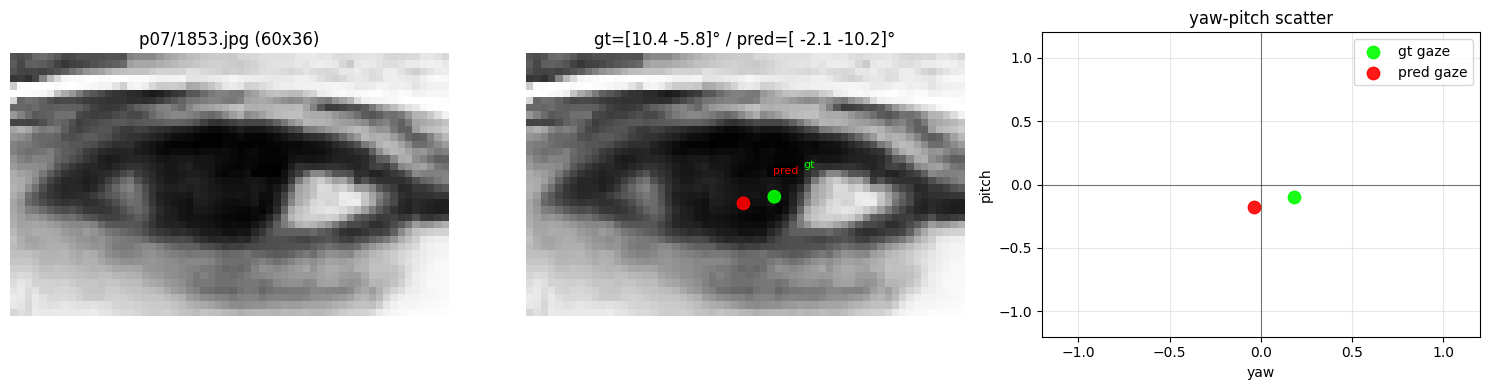

In [ ]:
# 3) 추론 및 결과 시각화
import matplotlib.pyplot as plt

# scatter 기반 시각화 함수

def plot_yaw_pitch_point(ax, yaw_pitch, color, label, size=80):
    ax.scatter(yaw_pitch[0], yaw_pitch[1], color=color, s=size, label=label, alpha=0.9)

# 랜덤 샘플 선택
rng = np.random.default_rng()
person = rng.choice(PERSONS)
dataset = reader.loader([str(LABEL_ROOT / f"{person}.label")], str(IMAGE_ROOT))
idx = int(rng.integers(0, len(dataset)))
info, label = dataset[idx]
eye = info["eye"]
head_pose = info["head_pose"]
gaze = label

model = GazeCNN()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

state_path = None
for candidate in [Path("gaze_cnn_p10.pt"), *sorted(Path(".").glob("gaze_cnn_*.pt"))]:
    if candidate.exists():
        state_path = str(candidate)
        break

if state_path is not None:
    state = torch.load(state_path, map_location=device)
    model.load_state_dict(state)
    print(f"Loaded model: {state_path}")
else:
    print("모델 파일을 찾지 못해 정답 gaze만 표시합니다.")

with torch.no_grad():
    eye_t = eye.astype(np.float32)[None, ...]
    head_t = head_pose.astype(np.float32)[None, ...]
    if IMG_MEAN is not None:
        eye_t = (eye_t - IMG_MEAN) / IMG_STD
        head_t = (head_t - HEAD_MEAN) / HEAD_STD
    eye_t = torch.from_numpy(eye_t).to(device)
    head_t = torch.from_numpy(head_t).to(device)
    pred = model(eye_t, head_t).cpu().numpy()[0] if state_path is not None else gaze.copy()

img = np.squeeze(eye, axis=0)
if img.ndim == 3:
    img = img[0]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1) 눈 이미지
axes[0].imshow(img, cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"{info['name']} ({img.shape[1]}x{img.shape[0]})")
axes[0].axis("off")

# 2) 이미지 상에서 gt/pred point 위치를 scatter로 표시
axes[1].imshow(img, cmap="gray", vmin=0, vmax=1)
scale = 0.65
x_gt = img.shape[1] / 2 + scale * np.sin(gaze[0]) * img.shape[1] / 2
y_gt = img.shape[0] / 2 - scale * np.sin(gaze[1]) * img.shape[0] / 2
x_pred = img.shape[1] / 2 + scale * np.sin(pred[0]) * img.shape[1] / 2
y_pred = img.shape[0] / 2 - scale * np.sin(pred[1]) * img.shape[0] / 2
axes[1].scatter([x_gt, x_pred], [y_gt, y_pred], c=["lime", "red"], s=80, alpha=0.9)
axes[1].text(x_gt + 4, y_gt - 4, "gt", color="lime", fontsize=8)
axes[1].text(x_pred + 4, y_pred - 4, "pred", color="red", fontsize=8)
axes[1].set_title(f"gt={np.degrees(gaze).round(1)}° / pred={np.degrees(pred).round(1)}°")
axes[1].axis("off")

# 3) yaw-pitch 산점도
axes[2].axhline(0, color="black", linewidth=0.8, alpha=0.5)
axes[2].axvline(0, color="black", linewidth=0.8, alpha=0.5)
plot_yaw_pitch_point(axes[2], gaze, "lime", "gt gaze", size=80)
plot_yaw_pitch_point(axes[2], pred, "red", "pred gaze", size=80)
axes[2].legend(loc="upper right")
axes[2].set_xlim(-1.2, 1.2)
axes[2].set_ylim(-1.2, 1.2)
axes[2].set_xlabel("yaw")
axes[2].set_ylabel("pitch")
axes[2].set_title("yaw-pitch scatter")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 학습 요약

이 노트북은 흐름을 정리하면 다음과 같습니다.

1. 데이터 정리: 이미지와 head pose를 읽고 통계량 계산
2. 모델 구성: CNN + head pose fusion
3. 학습: leave-one-person-out + cosine loss
4. 추론: 랜덤 샘플에 대해 예측값 시각화
5. 결과 분석: angular error와 방향성 비교

이 순서를 지키면 문제를 디버깅할 때 원인과 효과를 쉽게 분리해서 볼 수 있습니다.


In [1]:
# 4) 테스트 데이터셋 전체(또는 지정된 fold)에 대한 모델 추론 결과 산점도 시각화
test_person = "p00"
test_dataset = reader.loader([str(LABEL_ROOT / f"{test_person}.label")], str(IMAGE_ROOT))
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False, num_workers=2)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = GazeCNN().to(device)

model_path = Path(f"gaze_cnn_{test_person}.pt")
if not model_path.exists():
    candidates = sorted(Path(".").glob("gaze_cnn_*.pt"))
    if candidates:
        model_path = candidates[0]

if model_path.exists():
    model.load_state_dict(torch.load(model_path, map_location=device))
    print(f"Loaded weights from: {model_path}")
else:
    print("Warning: 저장된 가중치 파일이 없어 초기화된 모델로 추론합니다.")

model.eval()

preds = []
targets = []

with torch.no_grad():
    for info, label in test_loader:
        eye = info["eye"].float()
        head = info["head_pose"].float()
        if IMG_MEAN is not None:
            eye = (eye - torch.from_numpy(IMG_MEAN).float()) / torch.from_numpy(IMG_STD).float()
            head = (head - torch.from_numpy(HEAD_MEAN).float()) / torch.from_numpy(HEAD_STD).float()
        
        pred = model(eye.to(device), head.to(device))
        preds.append(pred.cpu().numpy())
        targets.append(label.numpy())

preds = np.concatenate(preds, axis=0)
targets = np.concatenate(targets, axis=0)

# 라디안 -> 도(degree) 단위 변환
preds_deg = np.degrees(preds)
targets_deg = np.degrees(targets)

errors = angular_error(preds, targets)
mean_err = np.mean(errors)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1) Yaw (정답 vs 예측)
axes[0].scatter(targets_deg[:, 0], preds_deg[:, 0], alpha=0.3, color="royalblue", edgecolors="none", s=18)
yaw_min = min(targets_deg[:, 0].min(), preds_deg[:, 0].min()) - 2
yaw_max = max(targets_deg[:, 0].max(), preds_deg[:, 0].max()) + 2
axes[0].plot([yaw_min, yaw_max], [yaw_min, yaw_max], "r--", linewidth=1.5, label="y = x (Ideal)")
axes[0].set_title(f"Yaw Estimation ({test_person})", fontsize=13)
axes[0].set_xlabel("Ground Truth Yaw (deg)", fontsize=11)
axes[0].set_ylabel("Predicted Yaw (deg)", fontsize=11)
axes[0].set_xlim(yaw_min, yaw_max)
axes[0].set_ylim(yaw_min, yaw_max)
axes[0].legend(loc="upper left")
axes[0].grid(True, linestyle=":", alpha=0.6)

# 2) Pitch (정답 vs 예측)
axes[1].scatter(targets_deg[:, 1], preds_deg[:, 1], alpha=0.3, color="darkorange", edgecolors="none", s=18)
pitch_min = min(targets_deg[:, 1].min(), preds_deg[:, 1].min()) - 2
pitch_max = max(targets_deg[:, 1].max(), preds_deg[:, 1].max()) + 2
axes[1].plot([pitch_min, pitch_max], [pitch_min, pitch_max], "r--", linewidth=1.5, label="y = x (Ideal)")
axes[1].set_title(f"Pitch Estimation ({test_person})", fontsize=13)
axes[1].set_xlabel("Ground Truth Pitch (deg)", fontsize=11)
axes[1].set_ylabel("Predicted Pitch (deg)", fontsize=11)
axes[1].set_xlim(pitch_min, pitch_max)
axes[1].set_ylim(pitch_min, pitch_max)
axes[1].legend(loc="upper left")
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.suptitle(f"Gaze Estimation Scatter Plot ({test_person}) - Mean Angular Error: {mean_err:.2f}°", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

NameError: name 'reader' is not defined